In [1]:
import cdflib
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('/home/lea/trampo/metrics')
from data_analysis import extract_coordinates
from compare_keypoints_3D import draw_skeleton


In [2]:
vit = ['Nose', 'REye', 'LEye', 'REar', 'LEar', 'RShoulder', 'LShoulder', 'RElbow', 'LElbow', 'RWrist', 'LWrist',
       'RHip', 'LHip', 'RKnee', 'LKnee', 'RAnkle', 'LAnkle']
pose2sim_vit = ['RHip', 'RKnee', 'RAnkle', 'LHip', 'LKnee', 'LAnkle', 'Nose',
                'RShoulder', 'RElbow', 'RWrist', 'LShoulder', 'LElbow', 'LWrist']

h36m = ['', 'RHip', 'RKnee', 'RAnkle', '', '', 'LHip', 'LKnee', 'LAnkle', '', '', '', '', '', 'Nose', '', '',
       'LShoulder', 'LElbow', 'LWrist', '', '', '', '', '', 'RShoulder', 'RElbow', 'RWrist', '', '', '', '']

common_indices_vit = [j for j in vit if j in pose2sim_vit]
matching_pose2sim_vit = [pose2sim_vit.index(j) for j in common_indices_vit]
matching_h36m_vit = [h36m.index(j) for j in common_indices_vit]

# define Rotation for Pose2Sim to World
R = np.array([[0, 0, 1],
              [1, 0, 0],
              [0, 1, 0]])

def get_gt_pose3d(gt_file):
    cdf_file = cdflib.CDF(gt_file)
    pose3d = cdf_file.varget('Pose').squeeze().reshape(-1, 3)
    return pose3d

def rotate_points(points, R):
    points_3d_r = (R @ points.T).T
    return points_3d_r

## Prototype

In [ ]:
gt_file = '/mnt/D494C4CF94C4B4F0/DATASETS_HPE/H36M/poses/S1/MyPoseFeatures/D3_Positions/Walking 1.cdf'

pose3d = get_gt_pose3d(gt_file)
pose3d = pose3d.reshape(-1, 32, 3)

pred_3d, frames = extract_coordinates('/home/lea/trampo/MODELS_2D3D/Pose2Sim/pose-3d-ViT-H36M-multi/S1_Walking 1/C1+C2+C3+C4/S1_Walking 1.trc')
pred_3d_r = rotate_points(pred_3d.reshape(-1, 3), R).reshape(pred_3d.shape)


In [114]:
print(pose3d.shape, pred_3d_r.shape)

for i, f in enumerate(frames):
    if i+1 != f:
        print("Frame mismatch:", i, f)

(3476, 32, 3) (2924, 13, 3)


## Plot joints in 3D

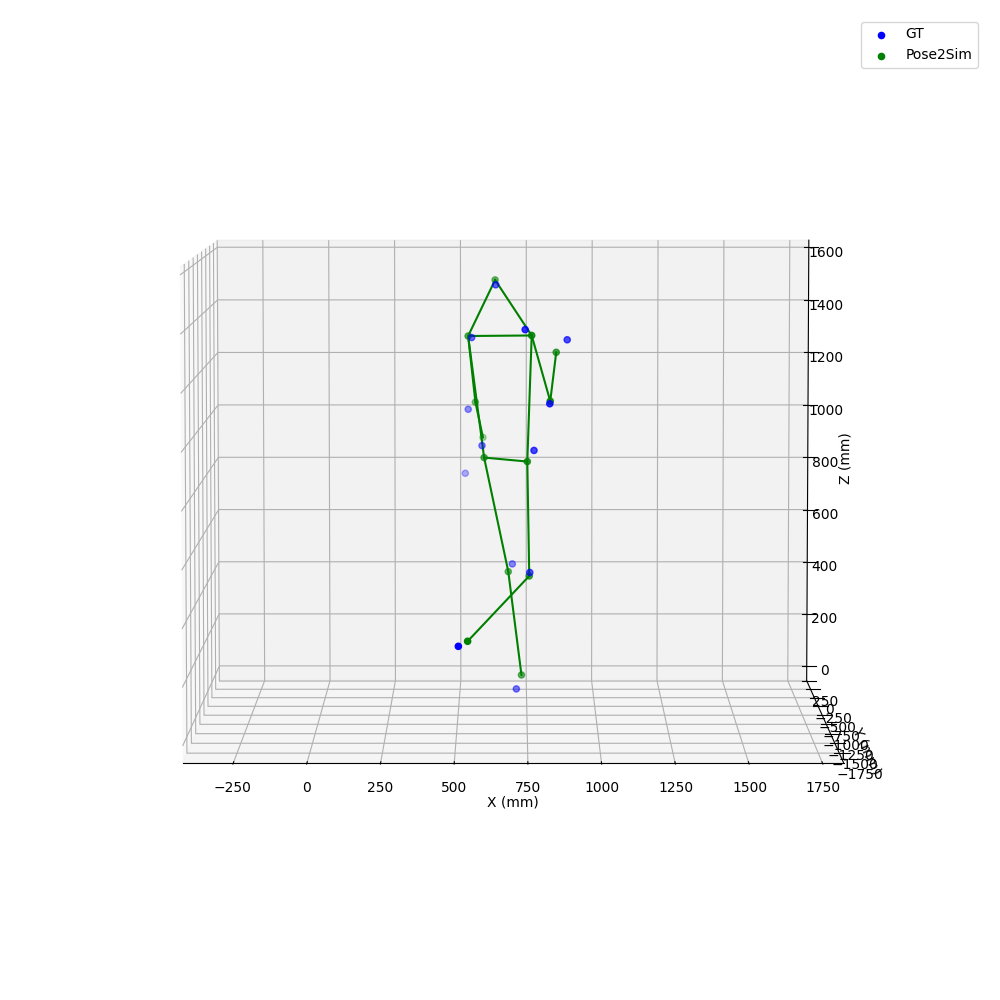

In [136]:
%matplotlib widget
plt.close('all')
fig = plt.figure(figsize=(10, 10))

# Plot original points
ax1 = fig.add_subplot(111, projection='3d')

f = 2357 # frame index

ax1.scatter(*pose3d[f, matching_h36m_vit].T, color='blue', label='GT')
ax1.scatter(*pred_3d_r[f, matching_pose2sim_vit].T, color='green', label='Pose2Sim')

#for j, joint in enumerate(pose3d[f]):
#    ax1.text(joint[0], joint[1], joint[2], j, color='black')
#draw_skeleton(pose3d[f, matching_vit], 'blue', ax, 'vit')
draw_skeleton(pred_3d_r[f, matching_pose2sim_vit], 'green', ax1, 'vit')

ax1.view_init(elev=5, azim=-90)
# Show plot
for ax in [ax1]:
    ax.set_aspect('equal', adjustable='datalim')
    ax.set_xlabel('X (mm)')
    ax.set_ylabel('Y (mm)')
    ax.set_zlabel('Z (mm)')

plt.legend()
plt.tight_layout()
plt.show()

## Quantitative comparison MPJPE

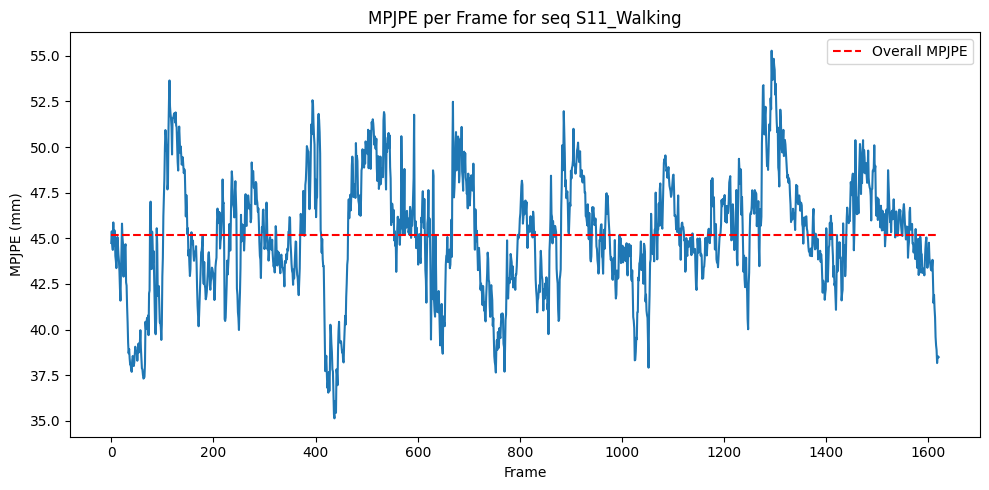

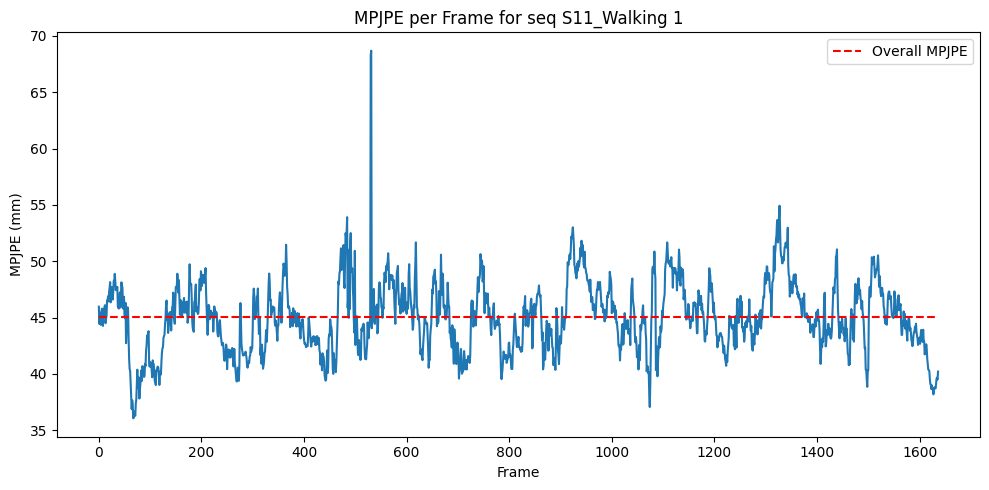

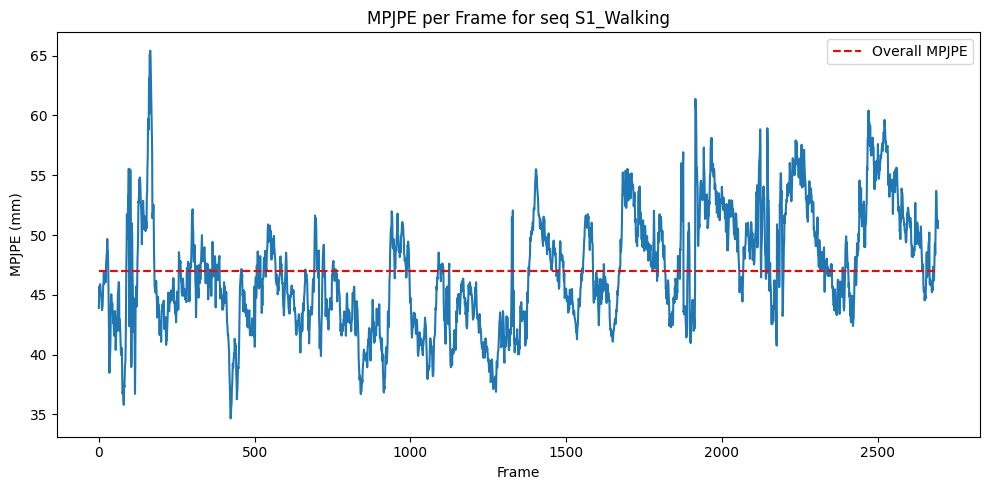

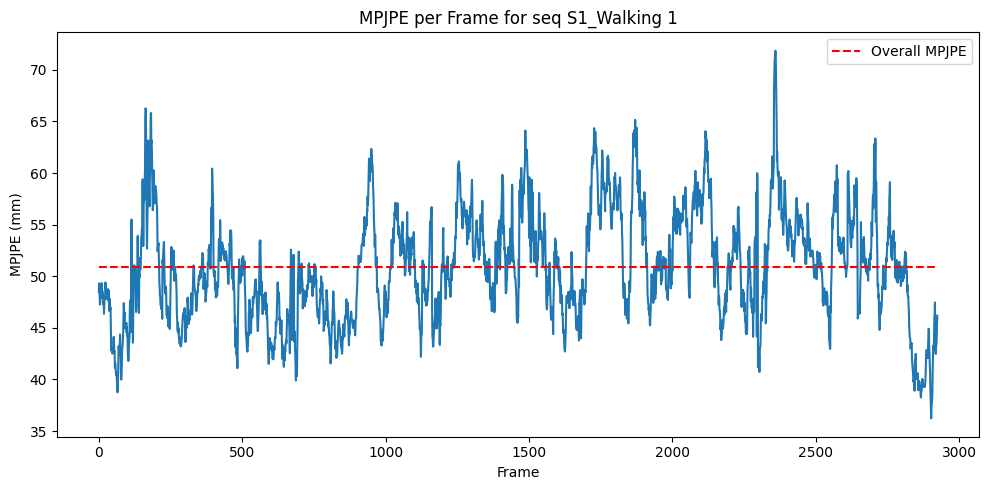

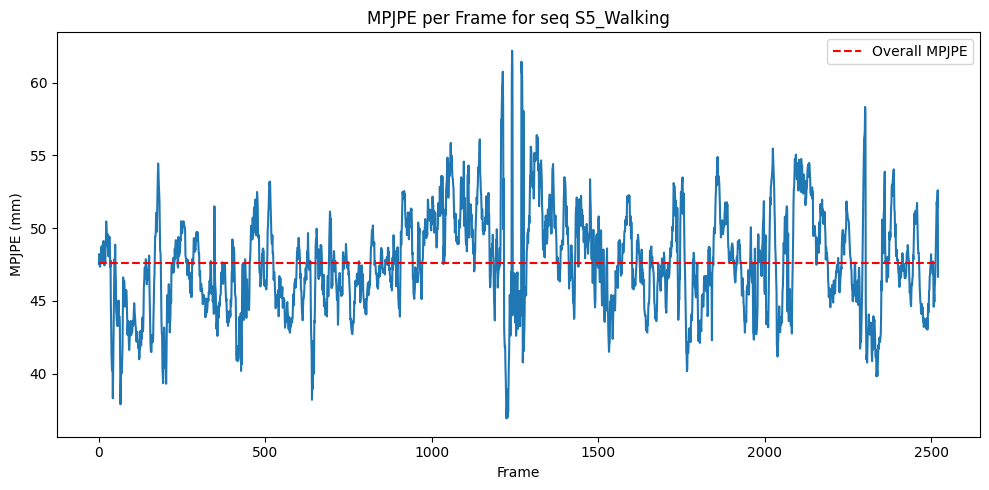

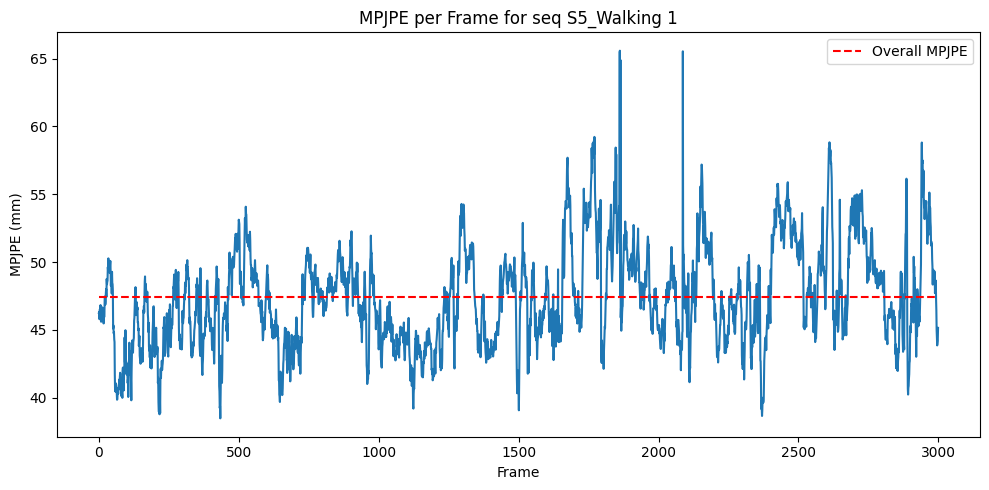

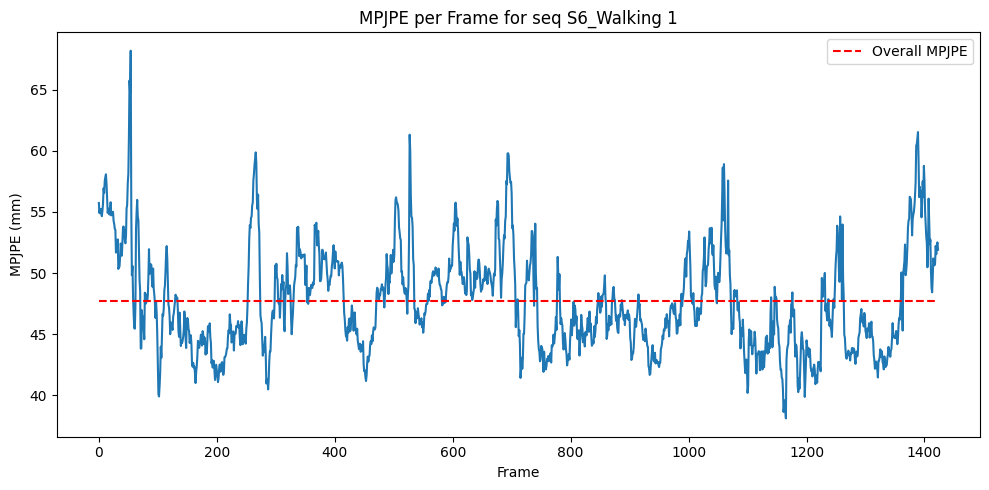

        GLOBAL MPJPE STATISTICS        
Global MPJPE (mm): 47.55
Global Median MPJPE (mm): 43.35
Global MPJPE Std Dev (mm): 26.07
Global MPJPE Min (mm): 0.74
Global MPJPE Max (mm): 317.98
Global MPJPE per joint:
Nose      : 91.22
RShoulder : 30.46
LShoulder : 42.52
RElbow    : 41.59
LElbow    : 27.23
RWrist    : 39.18
LWrist    : 27.30
RHip      : 84.96
LHip      : 57.36
RKnee     : 45.91
LKnee     : 25.90
RAnkle    : 47.88
LAnkle    : 56.62


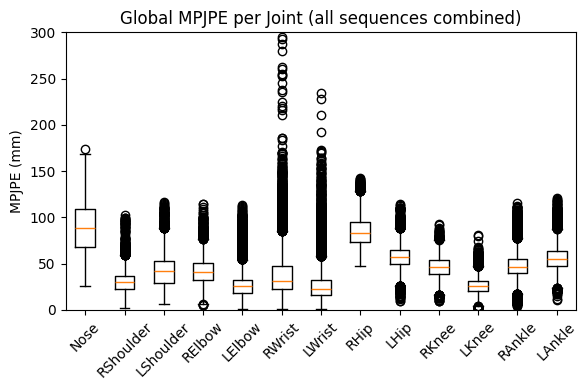

' # Global MPJPE distribution per frame\nall_mpjpe_per_frame_concat = np.concatenate(all_mpjpe_per_frame)\nplt.figure(figsize=(12,5))\nplt.plot(all_mpjpe_per_frame_concat)\nplt.hlines(global_mpjpe, xmin=0,\n           xmax=len(all_mpjpe_per_frame_concat)-1,\n           colors=\'red\', linestyles=\'--\', label=\'Global mean MPJPE\')\nplt.xlabel("Frame (all sequences)")\nplt.ylabel("MPJPE (mm)")\nplt.legend()\nplt.title("Global MPJPE per Frame (all sequences)")\nplt.tight_layout()\nplt.show() '

In [64]:
all_errors = []                 # list of arrays (num_frames, num_joints)
all_mpjpe_per_frame = []        # list of arrays (num_frames,)
all_mpjpe_per_joint = []        # list of arrays (num_joints,)
all_overall_mpjpe = []          # scalar per seq

root = '/home/lea/trampo/MODELS_2D3D/Pose2Sim/pose-3d-ViT-H36M-multi/'

for seq in sorted(os.listdir(root)):
    gt_file = f'/mnt/D494C4CF94C4B4F0/DATASETS_HPE/H36M/poses/{seq.split("_")[0]}/MyPoseFeatures/D3_Positions/{seq.split("_")[1]}.cdf'
    pred_file = f'{root}/{seq}/C1+C2+C3+C4/{seq}.trc'
    try:
        pose3d = get_gt_pose3d(gt_file)
    except FileNotFoundError:
        continue

    pose3d = pose3d.reshape(-1, 32, 3)

    pred_3d, frames = extract_coordinates(pred_file)
    pred_3d_r = rotate_points(pred_3d.reshape(-1, 3), R).reshape(pred_3d.shape)

    lenght = min(pose3d.shape[0], pred_3d_r.shape[0])
    gt = pose3d[:lenght, matching_h36m_vit]
    pred = pred_3d_r[:lenght, matching_pose2sim_vit]

    # Per-seq MPJPE calculation
    errors = np.linalg.norm(gt - pred, axis=2)    # (num_frames, num_joints)
    mpjpe_per_joint = np.nanmean(errors, axis=0)         # (num_joints,)
    mpjpe_per_frame = np.nanmean(errors, axis=1)         # (num_frames,)
    overall_mpjpe = np.nanmean(errors)

    # Store for global stats
    all_errors.append(errors)
    all_mpjpe_per_joint.append(mpjpe_per_joint)
    all_mpjpe_per_frame.append(mpjpe_per_frame)
    all_overall_mpjpe.append(overall_mpjpe)

    """ # Plot MPJPE distribution across joints with boxplots
    plt.figure(figsize=(10, 5))
    plt.boxplot(errors, tick_labels=common_indices_vit)
    plt.xticks(rotation=45)
    plt.ylabel('MPJPE (mm)')
    plt.title('MPJPE per Joint for seq ' + seq)
    plt.tight_layout()
    plt.show()  """

    # Plot MPJPE distribution across frames
    mpjpe_per_frame = np.nanmean(errors, axis=1) # shape (num_frames,)
    plt.figure(figsize=(10, 5))
    plt.plot(mpjpe_per_frame)
    plt.hlines(overall_mpjpe, xmin=0, xmax=len(mpjpe_per_frame)-1, colors='red', linestyle='--', label='Overall MPJPE')
    plt.legend()
    #plt.ylim(0, 75)
    plt.xlabel('Frame')
    plt.ylabel('MPJPE (mm)')
    plt.title('MPJPE per Frame for seq ' + seq)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------
# GLOBAL STATISTICS
# ---------------------------------------------------

# Concatenate everything
all_errors_concat = np.concatenate(all_errors, axis=0)  # (sum_frames, num_joints)
all_errors_concat = all_errors_concat[~np.isnan(all_errors_concat).any(axis=1)]

all_mpjpe_per_joint = np.mean(all_errors_concat, axis=0)
global_mpjpe = np.mean(all_errors_concat)
global_mpjpe_median = np.median(all_errors_concat)
global_mpjpe_std = np.std(all_errors_concat)
global_mpjpe_min = np.min(all_errors_concat)
global_mpjpe_max = np.max(all_errors_concat)

print("======================================")
print("        GLOBAL MPJPE STATISTICS        ")
print("======================================")
print(f"Global MPJPE (mm): {global_mpjpe:.2f}")
print(f"Global Median MPJPE (mm): {global_mpjpe_median:.2f}")
print(f"Global MPJPE Std Dev (mm): {global_mpjpe_std:.2f}")
print(f"Global MPJPE Min (mm): {global_mpjpe_min:.2f}")
print(f"Global MPJPE Max (mm): {global_mpjpe_max:.2f}")
print("======================================")
print("Global MPJPE per joint:")
for joint_name, mp in zip(common_indices_vit, all_mpjpe_per_joint):
    print(f"{joint_name:10s}: {mp:.2f}")

# Global boxplot
plt.figure(figsize=(6,4))
# remove nans from all_errors_concat
plt.boxplot(all_errors_concat, tick_labels=[common_indices_vit[i] for i in range(all_errors_concat.shape[1]) if not np.isnan(all_errors_concat[:, i]).all()])
plt.xticks(rotation=45)
plt.ylim(0, 300)
plt.ylabel("MPJPE (mm)")
plt.title("Global MPJPE per Joint (all sequences combined)")
plt.tight_layout()
plt.show()

""" # Global MPJPE distribution per frame
all_mpjpe_per_frame_concat = np.concatenate(all_mpjpe_per_frame)
plt.figure(figsize=(12,5))
plt.plot(all_mpjpe_per_frame_concat)
plt.hlines(global_mpjpe, xmin=0,
           xmax=len(all_mpjpe_per_frame_concat)-1,
           colors='red', linestyles='--', label='Global mean MPJPE')
plt.xlabel("Frame (all sequences)")
plt.ylabel("MPJPE (mm)")
plt.legend()
plt.title("Global MPJPE per Frame (all sequences)")
plt.tight_layout()
plt.show() """


